In [1]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
!pip install ucimlrepo

In [4]:
from ucimlrepo import fetch_ucirepo

# بارگذاری دیتاست سرطان سینه
breast_cancer = fetch_ucirepo(id=17)

X = breast_cancer.data.features
y = breast_cancer.data.targets

# بررسی اولیه
print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")
print(f"Target column name: {y.columns[0]}")
print(y.head())

Shape of X: (569, 30)
Shape of y: (569, 1)
Target column name: Diagnosis
  Diagnosis
0         M
1         M
2         M
3         M
4         M


In [5]:
# metadata
print(breast_cancer.metadata)

{'uci_id': 17, 'name': 'Breast Cancer Wisconsin (Diagnostic)', 'repository_url': 'https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic', 'data_url': 'https://archive.ics.uci.edu/static/public/17/data.csv', 'abstract': 'Diagnostic Wisconsin Breast Cancer Database.', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 569, 'num_features': 30, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['Diagnosis'], 'index_col': ['ID'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1993, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C5DW2B', 'creators': ['William Wolberg', 'Olvi Mangasarian', 'Nick Street', 'W. Street'], 'intro_paper': {'ID': 230, 'type': 'NATIVE', 'title': 'Nuclear feature extraction for breast tumor diagnosis', 'authors': 'W. Street, W. Wolberg, O. Mangasarian', 'venue': 'Electronic imaging', 'year': 1993, 'journal': None, 'DOI': '1

In [6]:
# variable information
print(breast_cancer.variables)

                  name     role         type demographic description units  \
0                   ID       ID  Categorical        None        None  None   
1            Diagnosis   Target  Categorical        None        None  None   
2              radius1  Feature   Continuous        None        None  None   
3             texture1  Feature   Continuous        None        None  None   
4           perimeter1  Feature   Continuous        None        None  None   
5                area1  Feature   Continuous        None        None  None   
6          smoothness1  Feature   Continuous        None        None  None   
7         compactness1  Feature   Continuous        None        None  None   
8           concavity1  Feature   Continuous        None        None  None   
9      concave_points1  Feature   Continuous        None        None  None   
10           symmetry1  Feature   Continuous        None        None  None   
11  fractal_dimension1  Feature   Continuous        None        

In [10]:
# ساخت دیتافریم یکپارچه
breast_cancer_df = pd.concat([X, y], axis=1)

# تبدیل هدف: M = 1 (بدخیم)، B = 0 (خوش‌خیم)
# نام ستون هدف در این دیتاست معمولاً Diagnosis است
target_col = y.columns[0]
breast_cancer_df[target_col] = breast_cancer_df[target_col].map({'M': 1, 'B': 0})

# تغییر نام ستون هدف به target برای سادگی
breast_cancer_df = breast_cancer_df.rename(columns={target_col: "target"})

In [11]:
# بررسی توزیع کلاس‌ها
print(breast_cancer_df["target"].value_counts(normalize=True))
print(breast_cancer_df.head())

target
0    0.627417
1    0.372583
Name: proportion, dtype: float64
   radius1  texture1  perimeter1   area1  smoothness1  compactness1  \
0    17.99     10.38      122.80  1001.0      0.11840       0.27760   
1    20.57     17.77      132.90  1326.0      0.08474       0.07864   
2    19.69     21.25      130.00  1203.0      0.10960       0.15990   
3    11.42     20.38       77.58   386.1      0.14250       0.28390   
4    20.29     14.34      135.10  1297.0      0.10030       0.13280   

   concavity1  concave_points1  symmetry1  fractal_dimension1  ...  texture3  \
0      0.3001          0.14710     0.2419             0.07871  ...     17.33   
1      0.0869          0.07017     0.1812             0.05667  ...     23.41   
2      0.1974          0.12790     0.2069             0.05999  ...     25.53   
3      0.2414          0.10520     0.2597             0.09744  ...     26.50   
4      0.1980          0.10430     0.1809             0.05883  ...     16.67   

   perimeter3   area3  s

In [12]:
import os
os.makedirs("/content/Datasets", exist_ok=True)
breast_cancer_df.to_csv(
    "/content/Datasets/breast_cancer.csv",
    index=False
)

In [13]:
#Datasets shape
print(f"Breast cancer : {breast_cancer_df.shape}")

Breast cancer : (569, 31)


In [14]:
#Datasets columns
print(f"Breast cancer : {breast_cancer_df.columns.tolist()}")

Breast cancer : ['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3', 'target']


In [15]:
#Datasets info
breast_cancer_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6   concavity1          569 non-null    float64
 7   concave_points1     569 non-null    float64
 8   symmetry1           569 non-null    float64
 9   fractal_dimension1  569 non-null    float64
 10  radius2             569 non-null    float64
 11  texture2            569 non-null    float64
 12  perimeter2          569 non-null    float64
 13  area2               569 non-null    float64
 14  smoothness2         569 non-null    float64
 15  compactness2        569 non-null    float64
 16  concavit

In [16]:
#Check null valuse
print(f"Breast cancer :\n{breast_cancer_df.isnull().sum()}\n")

print(f"Total nulls of breast cancer : {breast_cancer_df.isnull().sum().sum()}")

Breast cancer :
radius1               0
texture1              0
perimeter1            0
area1                 0
smoothness1           0
compactness1          0
concavity1            0
concave_points1       0
symmetry1             0
fractal_dimension1    0
radius2               0
texture2              0
perimeter2            0
area2                 0
smoothness2           0
compactness2          0
concavity2            0
concave_points2       0
symmetry2             0
fractal_dimension2    0
radius3               0
texture3              0
perimeter3            0
area3                 0
smoothness3           0
compactness3          0
concavity3            0
concave_points3       0
symmetry3             0
fractal_dimension3    0
target                0
dtype: int64

Total nulls of breast cancer : 0


In [17]:
#Counting the target values
print(f"Breast cancer :\n{breast_cancer_df["target"].value_counts()}\n")

#Counting target values normally
print(f"Breast cancer :\n{breast_cancer_df["target"].value_counts(normalize=True)}")

Breast cancer :
target
0    357
1    212
Name: count, dtype: int64

Breast cancer :
target
0    0.627417
1    0.372583
Name: proportion, dtype: float64


In [18]:
#Describe datasets
breast_cancer_df.describe()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.372583
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,0.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


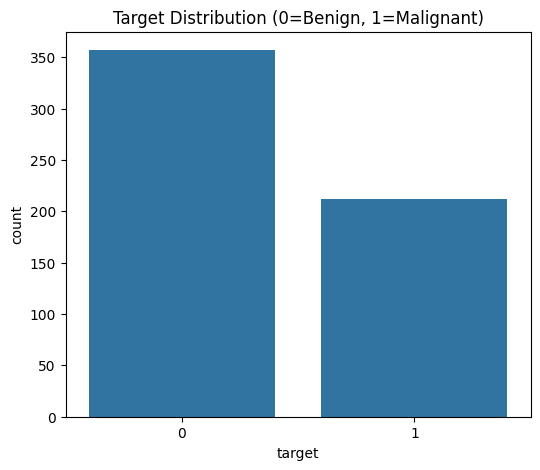

In [20]:
# توزیع هدف
plt.figure(figsize=(6, 5))
sns.countplot(data=breast_cancer_df, x="target")
plt.title("Target Distribution (0=Benign, 1=Malignant)")
plt.show()

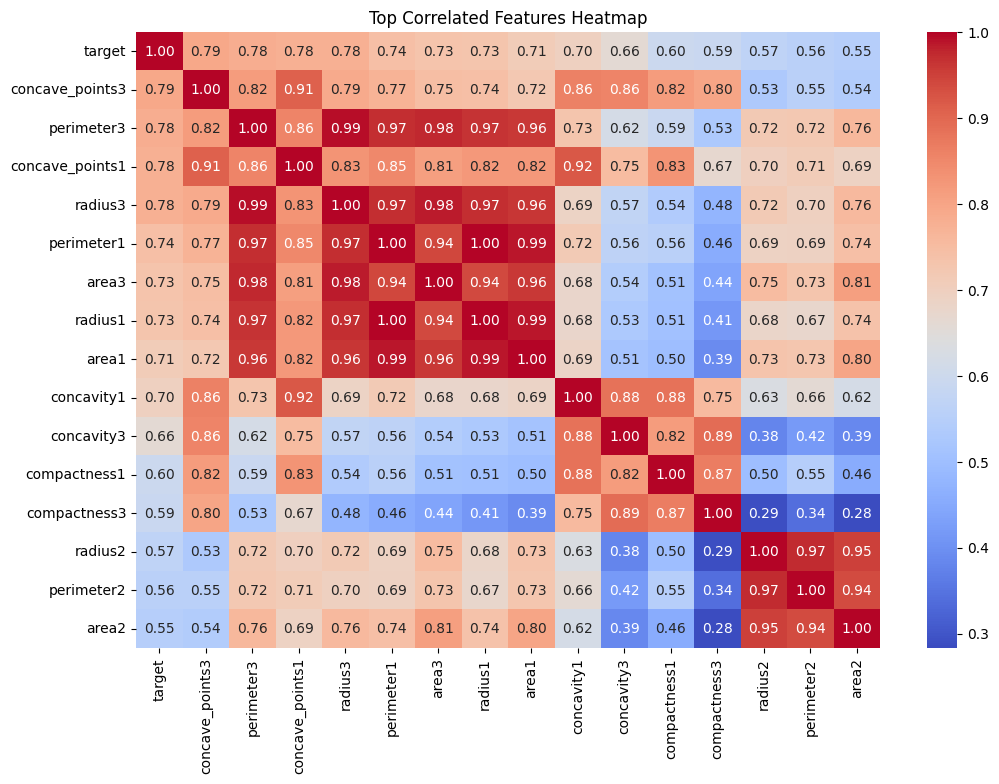

In [21]:
# ماتریس همبستگی (فقط ویژگی‌های با همبستگی بالا با هدف)
plt.figure(figsize=(12, 8))
correlation = breast_cancer_df.corr(numeric_only=True)
# نمایش ۱۵ ویژگی با بیشترین همبستگی با هدف
top_corr_features = correlation["target"].abs().sort_values(ascending=False).head(16).index
sns.heatmap(breast_cancer_df[top_corr_features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Top Correlated Features Heatmap")
plt.show()

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [24]:
# جدا کردن ویژگی‌ها و هدف
X = breast_cancer_df.drop("target", axis=1)
y = breast_cancer_df["target"]

# تقسیم Stratified
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# مقیاس‌بندی
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [26]:
# دیکشنری مدل‌ها
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine": SVC(kernel="rbf", probability=True, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
}

# آموزش و ارزیابی
results = []
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    })

results_df = pd.DataFrame(results).sort_values("F1-Score", ascending=False)
print(results_df.to_string(index=False))

                 Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
Support Vector Machine  0.973684   1.000000 0.928571  0.962963 0.994709
         Random Forest  0.973684   1.000000 0.928571  0.962963 0.992890
   Logistic Regression  0.964912   0.975000 0.928571  0.951220 0.996032
     Gradient Boosting  0.964912   1.000000 0.904762  0.950000 0.994709
   K-Nearest Neighbors  0.956140   0.974359 0.904762  0.938272 0.982308
         Decision Tree  0.929825   0.904762 0.904762  0.904762 0.924603
           Naive Bayes  0.921053   0.923077 0.857143  0.888889 0.989087


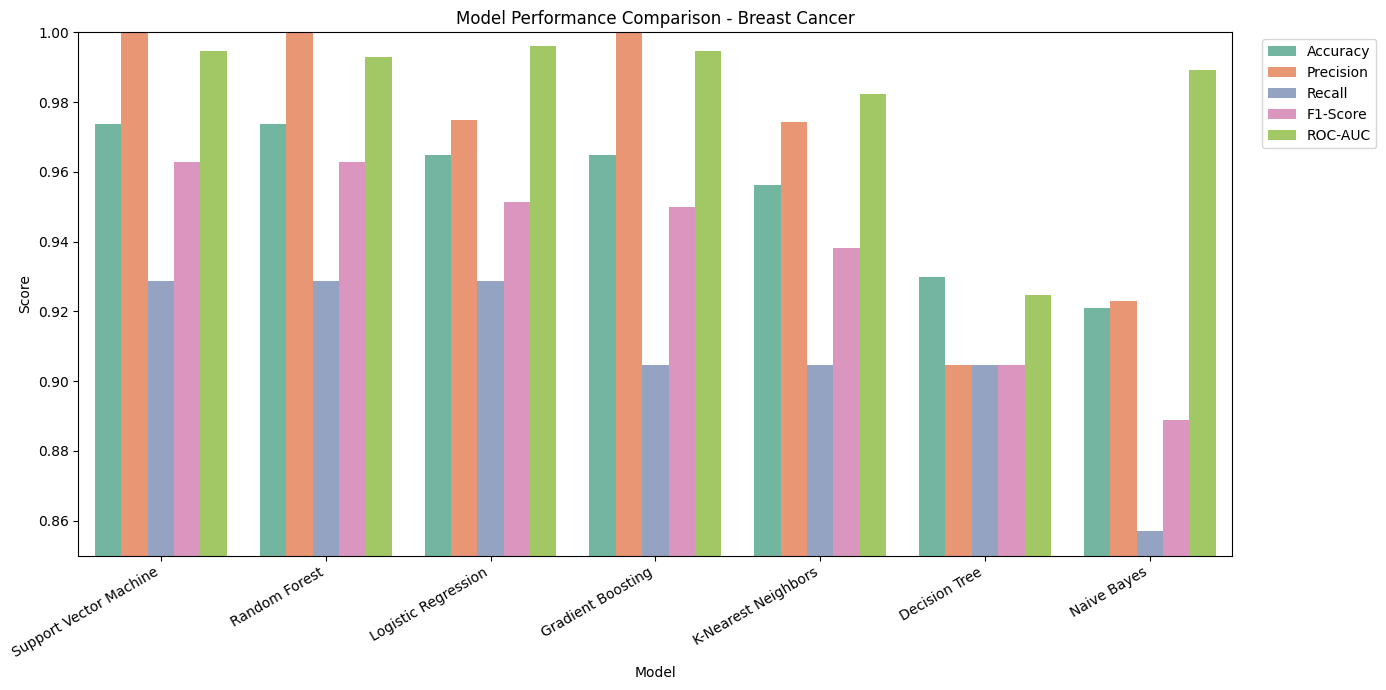

In [27]:
# نمودار مقایسه معیارها
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
results_melted = results_df.melt(id_vars="Model", value_vars=metrics, var_name="Metric", value_name="Score")

plt.figure(figsize=(14, 7))
sns.barplot(data=results_melted, x="Model", y="Score", hue="Metric", palette="Set2")
plt.title("Model Performance Comparison - Breast Cancer")
plt.xticks(rotation=30, ha="right")
plt.ylim(0.85, 1.0)  # چون دقت‌ها بالاست، بازه را تنظیم می‌کنیم
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [28]:
from sklearn.model_selection import GridSearchCV
import joblib

# تنظیم Random Forest
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train_scaled, y_train)

print(f"Best Params: {grid_search.best_params_}")
print(f"Best CV Score: {grid_search.best_score_:.4f}")

# ارزیابی روی تست
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test_scaled)
print(f"Tuned Test F1-Score: {f1_score(y_test, y_pred_tuned):.4f}")
print(f"Tuned Test Accuracy: {accuracy_score(y_test, y_pred_tuned):.4f}")

# ذخیره مدل و اسکیلر
joblib.dump(best_model, "/content/Datasets/best_breast_cancer_model.pkl")
joblib.dump(scaler, "/content/Datasets/breast_cancer_scaler.pkl")
print("✅ Model and scaler saved!")

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
Best CV Score: 0.9561
Tuned Test F1-Score: 0.9630
Tuned Test Accuracy: 0.9737
✅ Model and scaler saved!


Classification Report - Tuned Model:
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



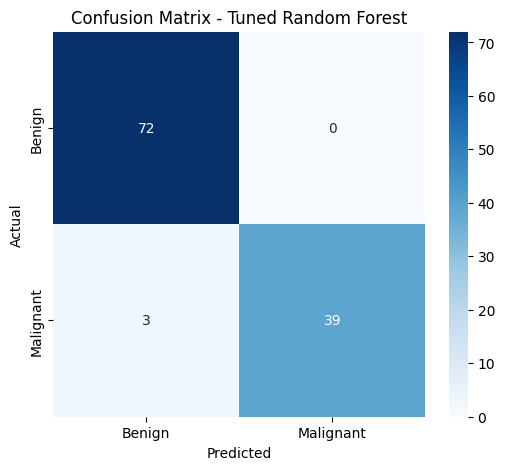

In [29]:
from sklearn.metrics import classification_report, confusion_matrix

print("Classification Report - Tuned Model:")
print(classification_report(y_test, y_pred_tuned, target_names=["Benign", "Malignant"]))

plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_tuned)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Benign", "Malignant"],
            yticklabels=["Benign", "Malignant"])
plt.title("Confusion Matrix - Tuned Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [30]:
# لیست نام ویژگی‌ها به همان ترتیبی که مدل دیده
feature_names = X.columns.tolist()

# یک نمونه نمونه (این مقادیر را از یک ردیف واقعی دیتاست برداشتم)
sample_dict = {name: X_test.iloc[0][name] for name in feature_names}

# ساخت دیتافریم با همان ترتیب ستون‌ها
sample_df = pd.DataFrame([sample_dict])[feature_names]

# پیش‌بینی
sample_scaled = scaler.transform(sample_df)
pred = model.predict(sample_scaled)[0]
proba = model.predict_proba(sample_scaled)[0][1]

print(f"Prediction: {'Malignant' if pred == 1 else 'Benign'}")
print(f"Malignant Probability: {proba:.2%}")

Prediction: Benign
Malignant Probability: 0.00%
